# 03 – Confusion matrix of the frozen model on the test split

Report figure for chapter 5.2 (Table 4 of the report). This notebook **does not fit, tune or choose anything**:
it loads the frozen model card `app/model/model.json` (logistic regression, monotone in the planned weight, threshold
chosen on validation) and the exported `split` column, and only *reports* on the test split that notebook 02 already
evaluated once (decision D-18). It refuses to run before that evaluation exists.

Outputs: the confusion matrix as a table and `docs/figures/confusion_matrix_test.png` (German labels for the report).

## 0. Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "specs" / "dataset_schema.json").exists():
            return candidate
    raise FileNotFoundError("Start Jupyter from inside the repository.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA = PROJECT_ROOT / "data" / "processed" / "deadlift3_attempts.parquet"
METADATA = json.loads((PROJECT_ROOT / "data" / "processed" / "metadata.json").read_text(encoding="utf-8"))
CARD = json.loads((PROJECT_ROOT / "app" / "model" / "model.json").read_text(encoding="utf-8"))
REFERENCE = json.loads((PROJECT_ROOT / "app" / "tests" / "reference_cases.json").read_text(encoding="utf-8"))
FIGURE = PROJECT_ROOT / "docs" / "figures" / "confusion_matrix_test.png"

if not DATA.exists():
    raise FileNotFoundError("Run notebooks/01_data_extraction_and_cleaning.ipynb first (refresh-dataset skill).")
if CARD["metrics"]["test"] is None:
    raise RuntimeError("The test split has not been evaluated yet – run notebook 02 with EVALUATE_TEST = True once.")
assert CARD["dataset"]["opl_commit"] == METADATA["source"]["opl_commit"], "dataset snapshot differs from the frozen model"
THRESHOLD = CARD["threshold"]
print(f"model {CARD['model_version']} · threshold {THRESHOLD} · test evaluated {CARD['metrics']['test']['evaluated_utc']}")

model monotone-logreg-v1 · threshold 0.3541 · test evaluated 2026-10-10T12:33:33+00:00


## 1. Predictions of the frozen model

Same feature formulas as `make_features()` in notebook 02 and `features()` in `app/js/model.js`. The check below
reproduces the reference probabilities of notebook 02 to 1e-9, so this copy cannot drift from the model.

In [2]:
KINKS = CARD["constants"]["jump_kinks"]
PB_CLIP = CARD["constants"]["pb_gap_clip"]
CATS = CARD["categories"]


def make_features(frame: pd.DataFrame, planned_kg: np.ndarray) -> pd.DataFrame:
    s = frame["dl2_success"].to_numpy(float)
    dl2 = frame["dl2_weight_kg"].to_numpy(float)
    bw = frame["bodyweight_kg"].to_numpy(float)
    pb = frame["prev_best_deadlift_kg"].to_numpy(float)
    has_pb = ~np.isnan(pb)
    pb_safe = np.where(has_pb, pb, 1.0)
    jump = np.log(np.asarray(planned_kg, float) / dl2)
    gap = np.where(has_pb, np.clip(np.log(dl2 / pb_safe), -PB_CLIP, PB_CLIP), 0.0)
    X = {"dl2_success": s, "rel_strength": np.log(dl2 / bw), "log_bodyweight": np.log(bw),
         "squat_ratio": np.log(frame["best_squat_kg"].to_numpy(float) / dl2),
         "bench_ratio": np.log(frame["best_bench_kg"].to_numpy(float) / dl2),
         "has_prev_best": has_pb.astype(float), "pb_gap": gap, "pb_gap_pos": np.maximum(gap, 0.0)}
    equipment, age = frame["equipment"].astype(str).to_numpy(), frame["age_class_group"].astype(str).to_numpy()
    for level in CATS["equipment"]:
        if level != CATS["equipment_baseline"]:
            X[f"equipment_{level}"] = (equipment == level).astype(float)
    for level in CATS["age_class_group"]:
        if level != CATS["age_baseline"]:
            X[f"age_{level}"] = (age == level).astype(float)
    X["jump_after_good"], X["jump_after_miss"] = jump * s, jump * (1 - s)
    for kink in KINKS:
        X[f"jump_over_{kink * 100:g}"] = np.maximum(0.0, jump - np.log1p(kink))
    X["pr_excess"] = np.where(has_pb, np.maximum(0.0, np.log(planned_kg / pb_safe)) - np.maximum(0.0, np.log(dl2 / pb_safe)), 0.0)
    return pd.DataFrame(X)


COEF = pd.Series(CARD["coefficients"])


def predict(frame: pd.DataFrame, planned_kg: np.ndarray) -> np.ndarray:
    X = make_features(frame, planned_kg)[COEF.index]
    return 1.0 / (1.0 + np.exp(-(CARD["intercept"] + X.to_numpy() @ COEF.to_numpy())))


ref = pd.DataFrame([c["context"] for c in REFERENCE["cases"]])
ref["dl2_success"] = ref["dl2_success"].astype(int)
ref["prev_best_deadlift_kg"] = ref["prev_best_deadlift_kg"].astype(float)
p_ref = predict(ref, np.array([c["planned_kg"] for c in REFERENCE["cases"]]))
assert np.max(np.abs(p_ref - np.array([c["p_fail"] for c in REFERENCE["cases"]]))) < 1e-9
print("features reproduce notebook 02 (", len(ref), "reference cases )")

features reproduce notebook 02 ( 40 reference cases )


## 2. Confusion matrix on the test split

In [3]:
df = pd.read_parquet(DATA)
test = df[df["split"] == "test"].reset_index(drop=True)
y_true = test["dl3_failed"].to_numpy().astype(int)
p_test = predict(test, test["dl3_weight_kg"].to_numpy())
y_pred = (p_test >= THRESHOLD).astype(int)

# rows = actual, columns = predicted; positive class 1 = "Versuch scheitert"
cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
(tp, fn), (fp, tn) = cm
precision, recall = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
assert abs(precision - CARD["metrics"]["test"]["precision"]) < 1e-4 and abs(recall - CARD["metrics"]["test"]["recall"]) < 1e-4

summary = {"TP (erkannt)": tp, "FN (übersehen)": fn, "FP (Fehlalarm)": fp, "TN (richtig entwarnt)": tn,
           "Precision": round(precision, 4), "Recall": round(recall, 4),
           "Spezifität": round(tn / (tn + fp), 4), "Accuracy": round((tp + tn) / cm.sum(), 4),
           "Accuracy Mehrheitsklasse": round((fp + tn) / cm.sum(), 4)}
table = pd.DataFrame(cm, index=["tatsächlich gescheitert", "tatsächlich gültig"],
                     columns=["Warnung (scheitert)", "keine Warnung (gelingt)"])
table.loc["Total"] = table.sum()
table["Total"] = table.sum(axis=1)
display(table)
pd.Series(summary)

,Warnung (scheitert),keine Warnung (gelingt),Total
tatsächlich gescheitert,35875,15217,51092
tatsächlich gültig,38601,42260,80861
Total,74476,57477,131953


TP (erkannt)                35875.0000
FN (übersehen)              15217.0000
FP (Fehlalarm)              38601.0000
TN (richtig entwarnt)       42260.0000
Precision                       0.4817
Recall                          0.7022
Spezifität                      0.5226
Accuracy                        0.5921
Accuracy Mehrheitsklasse        0.6128
dtype: float64

## 3. Figure for the report

Counts with the share of the actual class (row percentage). One sequential blue ramp encodes the row share;
the cell text states the numbers, so the figure does not rely on colour.

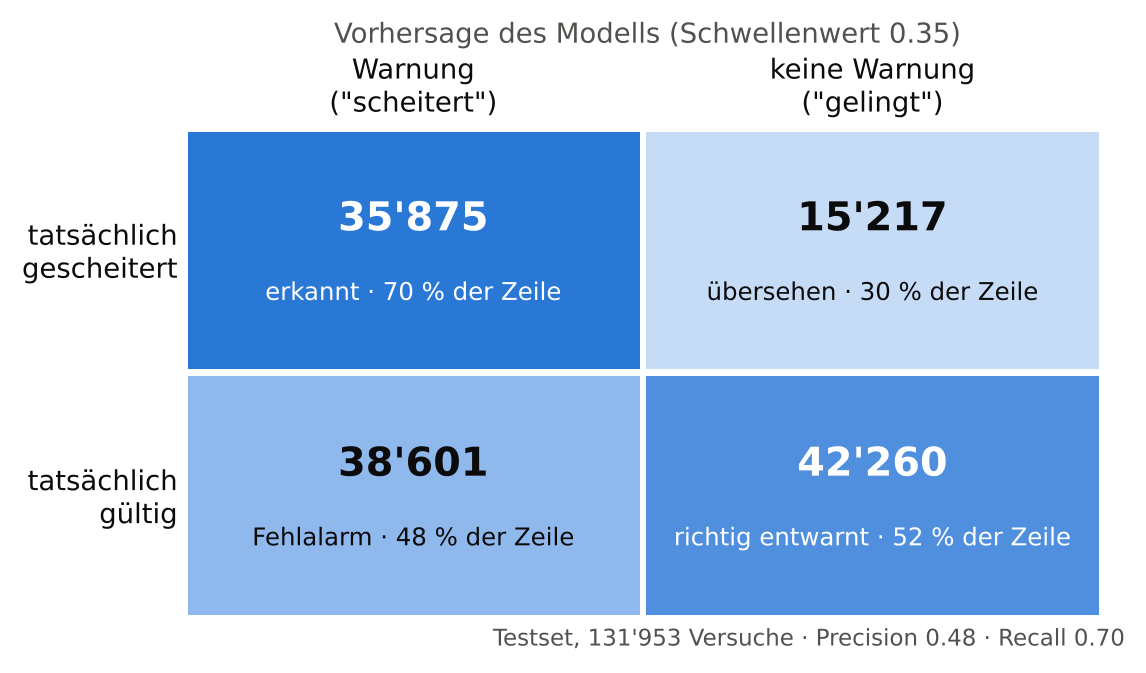

saved docs/figures/confusion_matrix_test.png


In [4]:
INK, MUTED = "#0b0b0b", "#52514e"
BLUE_RAMP = ["#eef4fc", "#c6dbf6", "#8fb8ec", "#4f8fde", "#2a78d6", "#1c5aa8"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9})

share = cm / cm.sum(axis=1, keepdims=True)
names = [["erkannt", "übersehen"], ["Fehlalarm", "richtig entwarnt"]]
fig, ax = plt.subplots(figsize=(5.2, 3.0), dpi=220)
for i in range(2):
    for j in range(2):
        level = min(int(share[i, j] * len(BLUE_RAMP)), len(BLUE_RAMP) - 1)
        ax.add_patch(plt.Rectangle((j, i), 0.98, 0.96, color=BLUE_RAMP[level]))
        ink = "white" if level >= 3 else INK
        ax.text(j + 0.49, i + 0.36, f"{cm[i, j]:,}".replace(",", "'"), ha="center", va="center", fontsize=13,
                fontweight="bold", color=ink)
        ax.text(j + 0.49, i + 0.66, f"{names[i][j]} · {share[i, j] * 100:.0f} % der Zeile", ha="center", va="center",
                fontsize=8, color=ink)
ax.set_xlim(0, 2); ax.set_ylim(2, 0)
ax.set_xticks([0.49, 1.49], ['Warnung\n("scheitert")', 'keine Warnung\n("gelingt")'])
ax.set_yticks([0.48, 1.48], ["tatsächlich\ngescheitert", "tatsächlich\ngültig"])
ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
ax.set_xlabel(f"Vorhersage des Modells (Schwellenwert {THRESHOLD:.2f})", color=MUTED)
ax.tick_params(length=0, colors=INK)
for side in ax.spines.values():
    side.set_visible(False)
n_total = f"{cm.sum():,}".replace(",", "'")
fig.text(0.99, 0.01, f"Testset, {n_total} Versuche · Precision {precision:.2f} · Recall {recall:.2f}",
         ha="right", fontsize=7.5, color=MUTED)
fig.tight_layout()
FIGURE.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE, bbox_inches="tight")
plt.show()
print("saved", FIGURE.relative_to(PROJECT_ROOT))